# MIE 446 Aerospace Structures
## Lecture 03 — Beam reactions, stress and deflection

**90-minute guided lesson · Dr. Ehsan Roohi · Fall 2026**

Lecture 02 converted distributed loads into a force and a load centroid. Today we ask what the structure must do with that load: **supports → reactions → internal shear and moment → stress → deflection**. The main model is a cantilever representing an idealized wing-root attachment. We compare two other supports without trying to cover every load/support combination.

By the end you should draw a free body, identify reaction unknowns, check equilibrium, calculate nominal bending stress and deflection, and explain why zero displacement at a clamp does not mean zero stress.

| Minutes | Activity | Evidence |
|---|---|---|
| 0–8 | Retrieve Lecture 02: force and centroid | Predict a root moment |
| 8–23 | Supports and reaction unknowns | Label a free-body diagram |
| 23–38 | Example A: cantilever and internal resultants | Calculate reaction, shear and moment |
| 38–53 | Stress across the section | Compute tension, compression and shear |
| 53–66 | Curvature and displacement | Calculate tip deflection and compare app |
| 66–78 | Example B: equivalent uniform load | Explain a same-force difference |
| 78–86 | Example C: support comparison | Explain why equilibrium is insufficient for fixed–fixed |
| 86–90 | Wing connection and exit ticket | Claim, number, check and limitation |

**Before class:** save a copy in Drive, run the setup, and open Wing Lab in another tab. All figures and baseline answers are saved, so the lesson is readable before execution. Python calculations run in Colab without installing CAD. App links open a new study with precisely the example inputs; they do not send edits back to this notebook. Modes, torsion and local buckling are for later lessons.

**Software:** [Open the beam workspace](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html) · [Lecture 02](https://colab.research.google.com/github/Ehsan-Roohi/Aerospace-Structures/blob/main/notebooks/MIE446_Lecture_02_Finite_Wings_and_Load_Paths.ipynb). The app and this notebook use mm, N and MPa. One MPa equals one N/mm².

In [1]:
#@title 0. Setup and clear plotting conventions
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon, Circle, FancyArrowPatch
plt.rcParams.update({'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 14,
                     'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
L, b, h, E, P = 450.0, 20.0, 10.0, 2000.0, 2.0
A = b*h
I = b*h**3/12
EI = E*I
x = np.linspace(0,L,401)
def arrow(ax, start, end, color='#9a2786'):
    ax.annotate('', xy=end, xytext=start,
                arrowprops=dict(arrowstyle='-|>', color=color, lw=2.5, mutation_scale=20))
def support(ax, at, kind):
    if kind == 'fixed':
        ax.add_patch(Rectangle((at-9,-14),9,28,facecolor='#c4d9cf',edgecolor='#176441',lw=2))
        for y in np.arange(-12,15,6): ax.plot([at-9,at-17],[y,y-5],color='#176441')
    else:
        ax.add_patch(Polygon([[at,0],[at-12,-12],[at+12,-12]],facecolor='#c4d9cf',edgecolor='#176441',lw=2))
        if kind == 'roller':
            for dx in [-7,7]: ax.add_patch(Circle((at+dx,-16),3,facecolor='white',edgecolor='#176441'))
def clean_beam(ax, title):
    ax.plot([0,L],[0,0],color='#19394e',lw=5)
    ax.set(xlim=(-55,510),ylim=(-55,65),title=title)
    ax.axis('off')
print(f'L={L:g} mm; b={b:g} mm; h={h:g} mm; E={E:g} MPa (assumed teaching value)')
print(f'A={A:g} mm²; I={I:.3f} mm⁴; EI={EI:.3f} N mm²')

L=450 mm; b=20 mm; h=10 mm; E=2000 MPa (assumed teaching value)
A=200 mm²; I=1666.667 mm⁴; EI=3333333.333 N mm²


## 1. What a support prevents and what it can transmit

A reaction is the force or moment that a support exerts to enforce a restricted motion. Do not draw a reaction moment at an ideal pin or roller: these allow rotation. A fixed support restricts rotation as well as translation.

| Ideal support in a planar model | Prevented motion | Reaction unknowns | Motion still allowed |
|---|---|---|---|
| Pin | Horizontal and vertical translation | $R_x,R_y$ | Rotation |
| Roller on a horizontal surface | Vertical translation | $R_y$ | Horizontal translation and rotation |
| Fixed clamp | Both translations and rotation | $R_x,R_y,M_A$ | None at the support |
| Free end | None | No support reaction | Translation and rotation |

These are idealizations, not descriptions of every bolt or bearing. A real wing attachment uses multiple fittings to transmit forces and a couple. In our **transverse-bending app**, only displacement $v$ and slope $\theta$ are solved: axial displacement is not a degree of freedom. Under purely transverse loading the planar horizontal reaction is zero, not an additional solved app result.

For a whole planar free body:

$$\sum F_x=0,\qquad \sum F_z=0,\qquad \sum M=0.$$

A pin–roller beam has three planar reaction unknowns and three equilibrium equations. Two fixed ends have six planar unknowns: equilibrium alone is insufficient. In transverse bending, four reactions $(R_A,M_A,R_B,M_B)$ need two equilibrium equations **plus displacement/rotation compatibility and stiffness**. Here no axial load is applied; the separate axial redundancy is outside the transverse model.

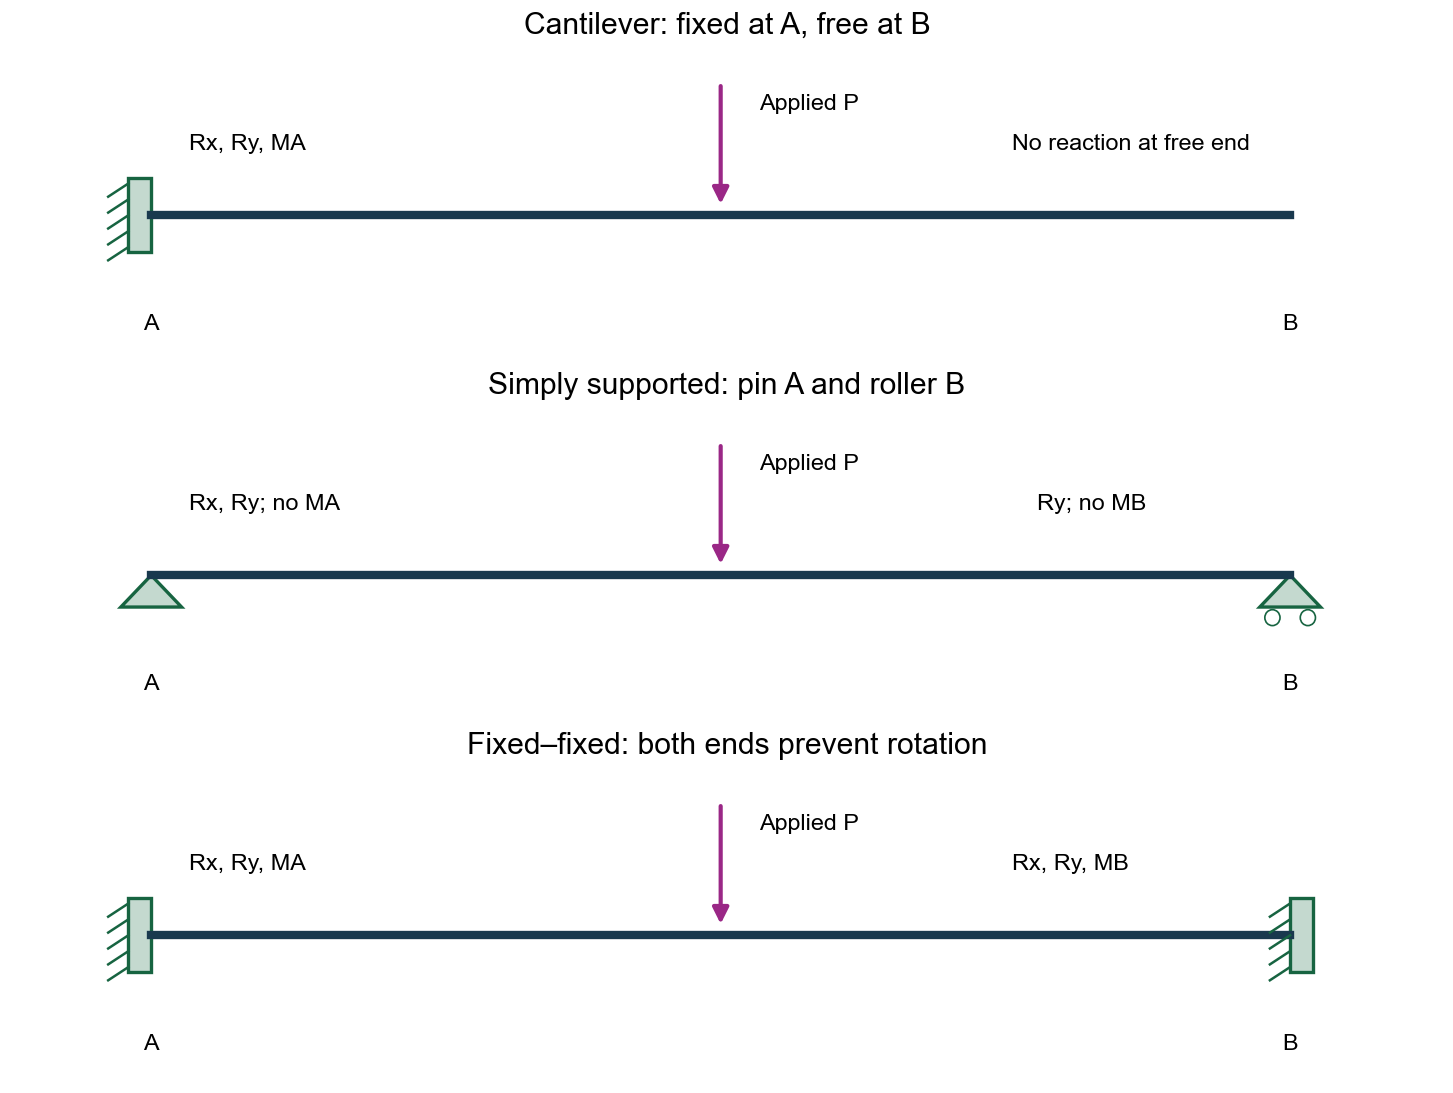

In [2]:
#@title Figure 1 — supports, permitted motions and reaction unknowns
fig, axes = plt.subplots(3,1,figsize=(12,9),layout='constrained')
for ax, title in zip(axes,['Cantilever: fixed at A, free at B',
                         'Simply supported: pin A and roller B',
                         'Fixed–fixed: both ends prevent rotation']):
    clean_beam(ax,title)
support(axes[0],0,'fixed')
support(axes[1],0,'pin'); support(axes[1],L,'roller')
support(axes[2],0,'fixed'); support(axes[2],L+9,'fixed')
for ax in axes:
    arrow(ax,(225,50),(225,3)); ax.text(240,40,'Applied P')
    ax.text(0,-43,'A',ha='center'); ax.text(L,-43,'B',ha='center')
axes[0].text(15,25,'Rx, Ry, MA'); axes[0].text(340,25,'No reaction at free end')
axes[1].text(15,25,'Rx, Ry; no MA'); axes[1].text(350,25,'Ry; no MB')
axes[2].text(15,25,'Rx, Ry, MA'); axes[2].text(340,25,'Rx, Ry, MB')
plt.show()

### Boundary conditions are not reactions

For small deflections, slope is rotation:

$$\theta$x$=\frac{dv}{dx}.$$

Fixed end: $v=0,\theta=0$. Simple support: $v=0$, rotation is free and the end bending moment is zero when no applied end couple is present. Unloaded free end: $V=0,M=0$. **A loaded free end is not force-free:** a tip force changes the shear boundary condition.

**Prediction:** can a point force placed exactly on a simple support bend the span? It can be taken directly by the support. For comparisons below the force is at midspan, not on a support.

## 2. Example A — a wing-like cantilever with a tip test load

Our rectangular PLA-like strip is a **teaching surrogate**, not the actual airfoil/wing box. Use $L=450$ mm, $b=20$ mm, vertical depth $h=10$ mm and assumed $E=2000$ MPa. Apply $P=2$ N downward at the free tip. Neglect self-weight; no load factor or extra weight is added automatically.

**Before calculating:** sketch the direction of the root force and root couple. Where should the largest displacement and largest moment occur?

Using upward-positive forces and counterclockwise-positive moments for this hand free body:

$$R_A-P=0,\qquad C_A-PL=0.$$

$$R_A=2\ \mathrm{N\ upward},\qquad C_A=900\ \mathrm{N\,mm\ counterclockwise}.$$

The **app** reports support force positive downward and support couple positive clockwise, so its reactions are **−2 N and −900 N mm**. These represent the same physical reactions. The reaction couple (C_A) is not the internal bending-moment sign at a section.

[Open and solve Example A — 2 N tip load](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-tip)

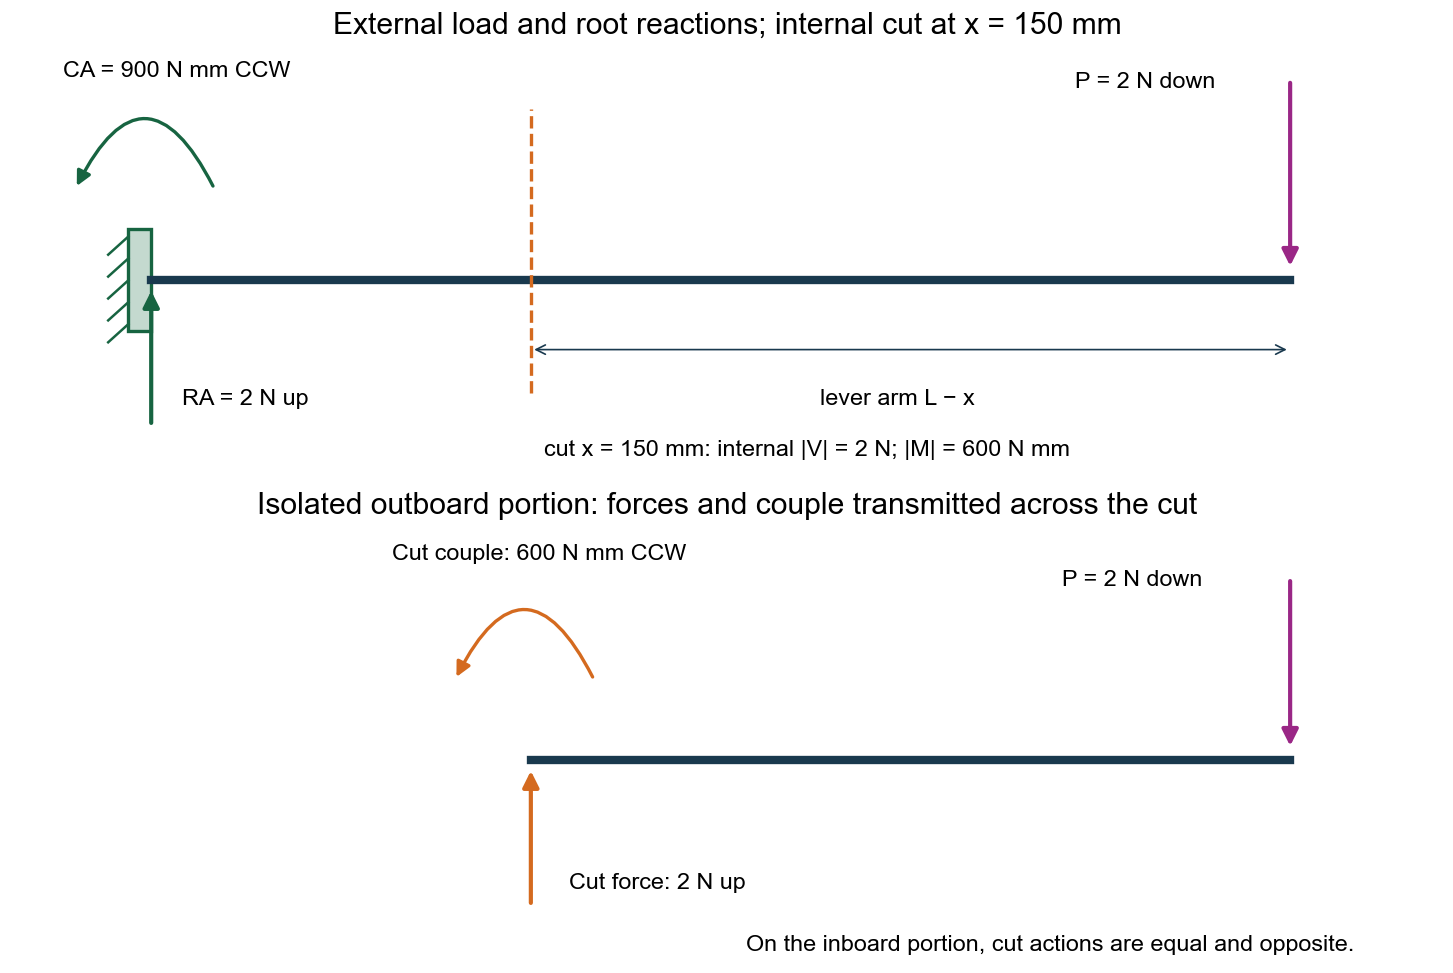

In [3]:
#@title Figure 2 — external free body and an outboard cut
fig, panels = plt.subplots(2,1,figsize=(12,8),layout='constrained')
ax=panels[0]
clean_beam(ax,'External load and root reactions; internal cut at x = 150 mm')
support(ax,0,'fixed')
arrow(ax,(L,55),(L,3)); ax.text(365,53,'P = 2 N down')
arrow(ax,(0,-40),(0,-2),'#176441'); ax.text(12,-34,'RA = 2 N up')
ax.add_patch(FancyArrowPatch((25,25),(-30,25),connectionstyle='arc3,rad=1',arrowstyle='-|>',mutation_scale=18,color='#176441',lw=2))
ax.text(-35,56,'CA = 900 N mm CCW')
ax.axvline(150,ymin=.2,ymax=.85,color='#d46a1f',ls='--',lw=2)
ax.text(155,-48,'cut x = 150 mm: internal |V| = 2 N; |M| = 600 N mm')
ax.annotate('',xy=(L,-19),xytext=(150,-19),arrowprops={'arrowstyle':'<->','color':'#19394e'})
ax.text(295,-34,'lever arm L − x',ha='center')
ax=panels[1]
clean_beam(ax,'Isolated outboard portion: forces and couple transmitted across the cut')
ax.lines[0].remove()
ax.plot([150,L],[0,0],color='#19394e',lw=5)
arrow(ax,(L,50),(L,3)); ax.text(360,48,'P = 2 N down')
arrow(ax,(150,-40),(150,-2),'#d46a1f'); ax.text(165,-35,'Cut force: 2 N up')
ax.add_patch(FancyArrowPatch((175,22),(120,22),connectionstyle='arc3,rad=1',arrowstyle='-|>',mutation_scale=18,color='#d46a1f',lw=2))
ax.text(95,55,'Cut couple: 600 N mm CCW')
ax.text(235,-52,'On the inboard portion, cut actions are equal and opposite.')
plt.show()

## 3. A cut reveals the internal shear and moment

Isolate the portion to the right of a cut at $x$. The tip force still acts on it. The cut must supply a shear force and bending moment to balance that portion. **Internal forces are not additional applied loads:** on opposite cut faces they form equal-and-opposite pairs.

Use the app convention throughout the following diagrams: downward load $q$ and deflection $v$ positive; positive internal $M$ is sagging; $z$ positive upward from the neutral axis.

$$V$x$=P,\qquad M$x$=-P(L-x),\qquad 0<x<L.$$

At (x=150) mm, (V=2) N and (M=-600) N mm. At the root-side section, $M=-900$ N mm. At the tip, (M=0). Shear has a jump at a point force; do not interpret a vertical jump as a finite-length triangular load.

For a distributed downward-positive load:

$$\frac{dV}{dx}=-q$x$,\qquad \frac{dM}{dx}=V$x$.$$

In words: load changes the shear; shear changes the moment. A constant shear produces a straight-line moment diagram.

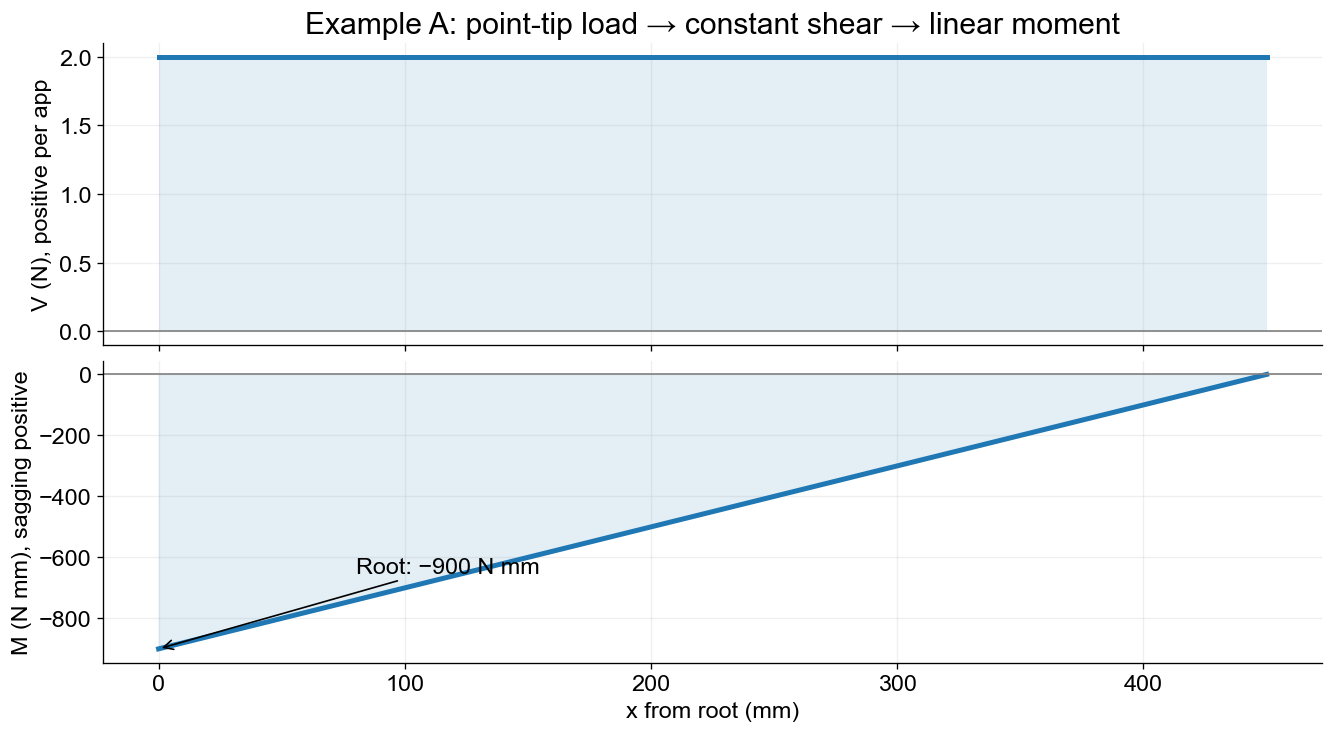

In [4]:
#@title Figure 3 — shear and moment along the cantilever
V = np.full_like(x,P)
M = -P*(L-x)
fig, axes = plt.subplots(2,1,figsize=(11,6),layout='constrained',sharex=True)
for ax,y,label in zip(axes,[V,M],['V (N), positive per app','M (N mm), sagging positive']):
    ax.plot(x,y,lw=3); ax.fill_between(x,y,0,alpha=.12); ax.axhline(0,color='gray',lw=1)
    ax.set_ylabel(label); ax.grid(alpha=.2)
axes[0].set_title('Example A: point-tip load → constant shear → linear moment')
axes[1].set_xlabel('x from root (mm)')
axes[1].annotate('Root: −900 N mm',xy=(0,-900),xytext=(80,-650),arrowprops={'arrowstyle':'->'})
plt.show()

## 4. From moment to bending stress

A bending moment produces longitudinal tension on one side and compression on the other. In a homogeneous beam the neutral axis passes through the section centroid; bending normal stress is zero there.

$$A=bh=200\ \mathrm{mm^2},\qquad I=\frac{bh^3}{12}=1666.67\ \mathrm{mm^4}.$$

$$\boxed{\sigma_x(x,z)=-\frac{M$x$z}{I}},\qquad
\boxed{|\sigma_{\max}|=\frac{|M|c}{I}},\qquad c=\frac{h}{2}.$$


Here $I$ is the **second moment of area**, not mass moment of inertia. Its mm⁴ units make $(\mathrm{N\,mm})(\mathrm{mm})/\mathrm{mm^4}=\mathrm{N/mm^2}$. Stress is positive in tension. At the root under downward loading, $M=-900$: top $z=+5$ has $+2.70$ MPa tension; bottom has $-2.70$ MPa compression. **Upward wing lift reverses these signs:** top compression, bottom tension.

The formula is nominal beam stress away from local details. It does not resolve bolt holes, clamp contact or stress concentrations, and does not predict buckling. A fixed end can carry a large moment while its displacement remains zero.

### Shear stress is different from bending stress

For a solid rectangle, transverse shear stress is parabolic across the depth:

$$\tau_{xz}$z$=\frac{3V}{2A}\left[1-\left(\frac{2z}{h}\right)^2\right],\qquad
|\tau_{\max}|=\frac{3|V|}{2A}=0.015\ \mathrm{MPa}.$$

It is maximum at the neutral axis and zero at top/bottom surfaces. Do not combine this maximum shear with maximum bending as if they occur at the same location. For a wing box, caps/skins carry bending and webs/skins carry shear; the solid-rectangle shear formula is not a wing-web formula.

Root top stress = 2.700 MPa; bottom = -2.700 MPa
Neutral-axis maximum transverse shear = 0.0150 MPa


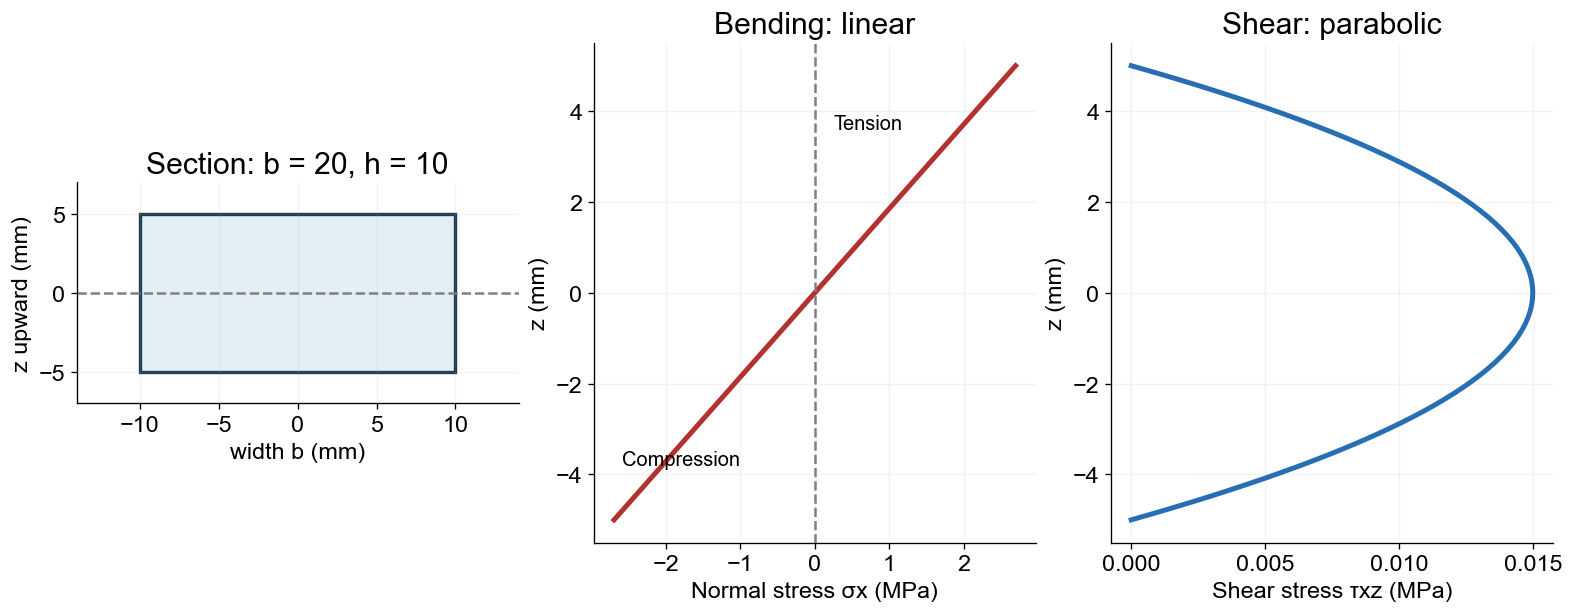

In [5]:
#@title Figure 4 — stress through the root section
z=np.linspace(-h/2,h/2,151)
sigma=-(-P*L)*z/I
tau=1.5*P/A*(1-(2*z/h)**2)
fig,axes=plt.subplots(1,3,figsize=(13,5),layout='constrained')
axes[0].add_patch(Rectangle((-b/2,-h/2),b,h,facecolor='#e3eef5',edgecolor='#19394e',lw=2))
axes[0].axhline(0,color='gray',ls='--'); axes[0].set(xlim=(-14,14),ylim=(-7,7),xlabel='width b (mm)',ylabel='z upward (mm)',title='Section: b = 20, h = 10')
axes[0].set_aspect('equal')
axes[1].plot(sigma,z,lw=3,color='#b1322e'); axes[1].axvline(0,color='gray',ls='--')
axes[1].set(xlabel='Normal stress σx (MPa)',ylabel='z (mm)',title='Bending: linear')
axes[1].text(-2.6,-3.8,'Compression',fontsize=12); axes[1].text(.25,3.6,'Tension',fontsize=12)
axes[2].plot(tau,z,lw=3,color='#276eb3'); axes[2].set(xlabel='Shear stress τxz (MPa)',ylabel='z (mm)',title='Shear: parabolic')
for ax in axes: ax.grid(alpha=.15)
plt.show()
print(f'Root top stress = {P*L*h/2/I:.3f} MPa; bottom = {-P*L*h/2/I:.3f} MPa')
print(f'Neutral-axis maximum transverse shear = {1.5*P/A:.4f} MPa')

## 5. From curvature to displacement

Strain describes how a small piece changes length; stress is force per area; displacement describes the motion of a point. These are different outputs.

$$\varepsilon_x=z\frac{d^2v}{dx^2},\qquad \sigma_x=E\varepsilon_x,\qquad
M=-EI\frac{d^2v}{dx^2}.$$

The moment sets curvature. Integrating once gives slope; integrating again gives displacement. Integration constants are found from the supports, not guessed. With our signs and constant $EI$:

$$EI\frac{d^4v}{dx^4}=q$x$.$$

For Example A, $v(0)=0$ and $v'(0)=0$:

$$\theta$x$=\frac{Px(2L-x)}{2EI},\qquad
v$x$=\frac{Px^2(3L-x)}{6EI}.$$

$$\boxed{v(L)=\frac{PL^3}{3EI}=18.225\ \mathrm{mm}}.$$

The tip slope is 0.06075 rad (about 3.48°). The predicted deflection is about 4.05% of span. This is an ideal linear-elastic small-deflection result; check whether that approximation and the assumed printed-material modulus are adequate before using it to judge an actual test. Do not infer a real printed wing's stiffness from this solid-strip example.

Tip deflection = 18.2250 mm; root deflection = 0.0000 mm
Tip slope = 0.06075 rad


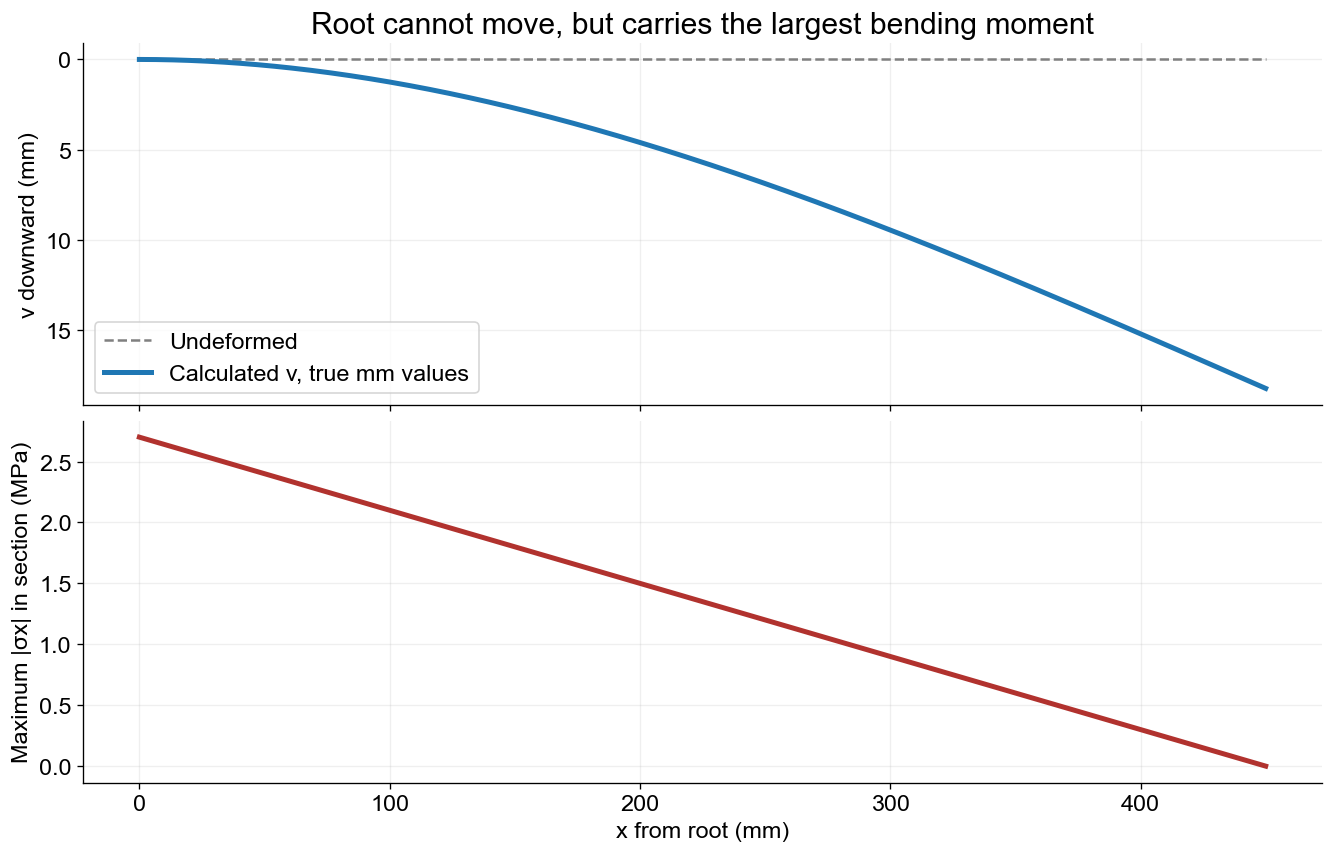

In [6]:
#@title Figure 5 — undeformed and deflected shape; stress is not displacement
v=P*x**2*(3*L-x)/(6*EI)
fig,axes=plt.subplots(2,1,figsize=(11,7),layout='constrained',sharex=True)
axes[0].plot(x,np.zeros_like(x),'--',color='gray',label='Undeformed')
axes[0].plot(x,v,lw=3,label='Calculated v, true mm values')
axes[0].invert_yaxis(); axes[0].set_ylabel('v downward (mm)'); axes[0].legend()
axes[0].set_title('Root cannot move, but carries the largest bending moment')
axes[1].plot(x,np.abs(M)*h/2/I,lw=3,color='#b1322e')
axes[1].set(xlabel='x from root (mm)',ylabel='Maximum |σx| in section (MPa)')
for ax in axes: ax.grid(alpha=.2)
plt.show()
print(f'Tip deflection = {v[-1]:.4f} mm; root deflection = {v[0]:.4f} mm')
print(f'Tip slope = {P*L**2/(2*EI):.5f} rad')

### What the app actually solves

The app divides the beam into finite elements. Each node has a displacement and rotation. Element stiffness and consistent loads assemble into:

$$\mathbf K\mathbf u=\mathbf f.$$

Boundary conditions restrict selected components of $\mathbf u$. After solving the free components, the original equations recover reactions. The app reconstructs shear and moment from equilibrium and evaluates stress. Refining the mesh checks numerical sensitivity; it does not verify a real clamp, printed anisotropy or material strength. You do not need to derive element matrices today.

**Software activity A:** open the tip-load link. Find −2 N, −900 N mm, 2.70 MPa and 18.225 mm. Use the probe at 150 mm and check (M=-600) N mm. Explain any sign differences before declaring an error. Download the study record.

## 6. Example B — uniform pressure reduced to a line load

For an illustrative wing strip, a uniform pressure $p$ over loaded width $c_{\mathrm{loaded}}$ gives $q=p c_{\mathrm{loaded}}$. This is an applied-load idealization, not a predicted aerodynamic lift distribution. Here choose the full-span line load to have the **same 2 N total** as Example A:

$$q=\frac{F}{L}=\frac{2}{450}=0.00444444\ \mathrm{N/mm}.$$

Its resultant acts at $L/2$, so:

$$|C_A|=\frac{qL^2}{2}=450\ \mathrm{N\,mm},\qquad
|\sigma_{\mathrm{root}}|=\frac{qL^2h}{4I}=1.35\ \mathrm{MPa}.$$

$$v(L)=\frac{qL^4}{8EI}=6.834375\ \mathrm{mm}.$$

The root force is unchanged, root moment is half, and tip displacement is **3/8** of the point-tip case. Replacing a distributed load by its resultant gives the correct **whole-beam reactions**, but generally not the same internal diagrams or deflection. A centroid-point load of 2 N at midspan gives 5.695313 mm at the free tip, not 6.834375 mm.

**Prediction:** if we change only the direction to upward lift, what changes sign and what keeps its magnitude?

[Open and solve Example B — uniform 2 N downward](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-uniform) · [Open and solve Example B extension — uniform upward lift](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-lift)

Uniform: root |M|=450.000 N mm; stress=1.350 MPa; tip v=6.834375 mm


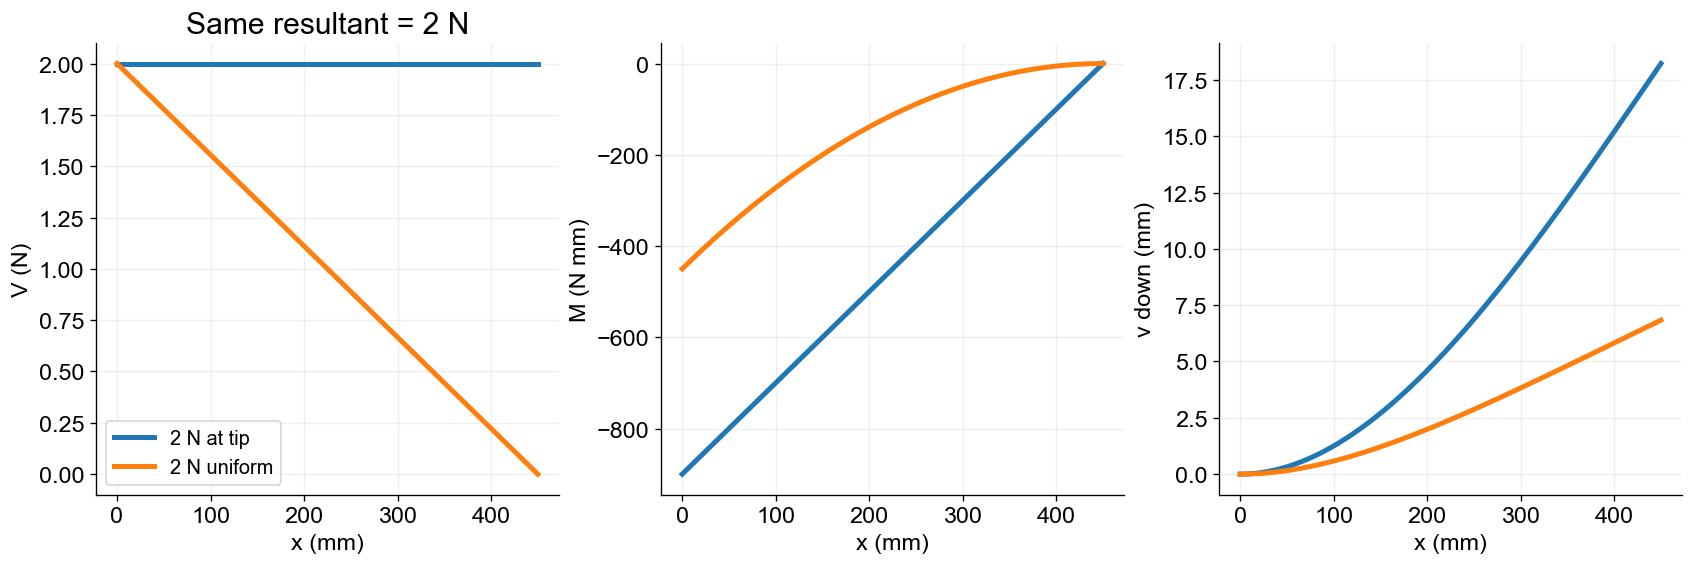

In [7]:
#@title Figure 6 — equal total load, different internal diagrams and displacement
q=P/L
Vu=q*(L-x); Mu=-q*(L-x)**2/2
vu=q*x**2*(6*L**2-4*L*x+x*x)/(24*EI)
fig,axes=plt.subplots(1,3,figsize=(14,4.6),layout='constrained')
for ax,y1,y2,label in zip(axes,[V,M,v],[Vu,Mu,vu],['V (N)','M (N mm)','v down (mm)']):
    ax.plot(x,y1,lw=3,label='2 N at tip'); ax.plot(x,y2,lw=3,label='2 N uniform')
    ax.set(xlabel='x (mm)',ylabel=label); ax.grid(alpha=.2)
axes[0].legend(fontsize=12); axes[0].set_title('Same resultant = 2 N')
plt.show()
print(f'Uniform: root |M|={q*L**2/2:.3f} N mm; stress={q*L**2*h/(4*I):.3f} MPa; tip v={vu[-1]:.6f} mm')

## 7. Example C — change only the support conditions

Keep $P=2$ N, $L=450$ mm, the same section and $E$, but place the load at **midspan**. This might represent a laboratory coupon tested between fixtures. It is not a second aircraft wing-root model.

For the symmetric simply supported beam, equilibrium gives $R_A=R_B=P/2$. Neither support supplies an end moment:

$$M_{\max}=\frac{PL}{4}=225\ \mathrm{N\,mm},\qquad
|\sigma_{\max}|=0.675\ \mathrm{MPa},\qquad
v_{\max}=\frac{PL^3}{48EI}=1.139063\ \mathrm{mm}.$$

For the symmetric fixed–fixed beam, compatibility produces end hogging moments $M(0)=M(L)=-PL/8$ and centre sagging moment $+PL/8$:

$$|M|_{\max}=\frac{PL}{8}=112.5\ \mathrm{N\,mm},\qquad
|\sigma_{\max}|=0.3375\ \mathrm{MPa},\qquad
v_{\max}=\frac{PL^3}{192EI}=0.284766\ \mathrm{mm}.$$

Its app reactions are −1 N at each end, with clockwise-positive couples **−112.5 N mm at A and +112.5 N mm at B**. This is why support reaction-couple signs and internal moment signs should not be interchanged. A fixed–fixed beam can have maximum stress at both supports and at the centre for this symmetric load. Clamping changes the moment distribution; it does not merely multiply every stress by a universal factor.

We use these standard results today; a full compatibility derivation is after-class work. Do not try to solve the redundant end moments using equilibrium alone.

[Open and solve Example C1 — pin–roller and centre load](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-simple) · [Open and solve Example C2 — fixed–fixed and centre load](https://ehsan-roohi.github.io/Aerospace-Structures/wing-lab.html?beamCase=l03-fixed)

Pin–roller: max |M|=225.0000 N mm; max |σ|=0.675000 MPa; max v=1.139063 mm
Fixed–fixed: max |M|=112.5000 N mm; max |σ|=0.337500 MPa; max v=0.284766 mm


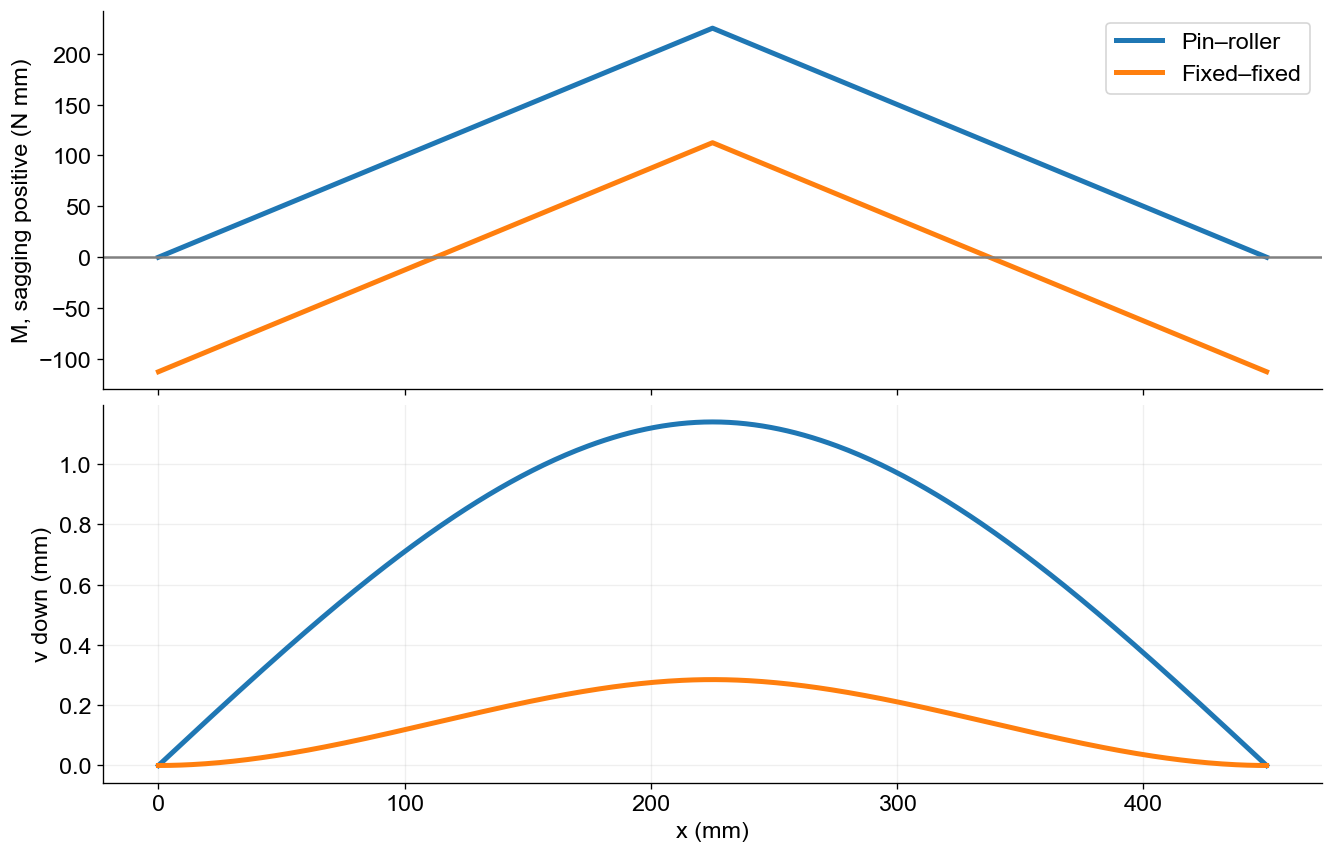

In [8]:
#@title Figure 7 — simply supported versus fixed–fixed, same centre force
Ms=np.where(x<=L/2,P*x/2,P*(L-x)/2)
Mf=Ms-P*L/8
xx=np.minimum(x,L-x)
vs=P*xx*(3*L**2-4*xx**2)/(48*EI)
vf=P*xx**2*(3*L-4*xx)/(48*EI)
fig,axes=plt.subplots(2,1,figsize=(11,7),layout='constrained',sharex=True)
axes[0].plot(x,Ms,lw=3,label='Pin–roller'); axes[0].plot(x,Mf,lw=3,label='Fixed–fixed')
axes[0].axhline(0,color='gray'); axes[0].set_ylabel('M, sagging positive (N mm)'); axes[0].legend()
axes[1].plot(x,vs,lw=3,label='Pin–roller'); axes[1].plot(x,vf,lw=3,label='Fixed–fixed')
axes[1].set(xlabel='x (mm)',ylabel='v down (mm)'); axes[1].grid(alpha=.2)
plt.show()
for name,mm,vv in [('Pin–roller',Ms,vs),('Fixed–fixed',Mf,vf)]:
    print(f'{name}: max |M|={max(abs(mm)):.4f} N mm; max |σ|={max(abs(mm))*h/(2*I):.6f} MPa; max v={max(vv):.6f} mm')

## 8. Return to the aircraft wing

For an upward-loaded wing, top material is commonly in spanwise compression and bottom material in tension under positive lift bending. The root transfers shear and a bending couple to the fuselage. In a deep spar, the caps carry much of the bending tension/compression and the web carries shear. Skins and stringers also participate; ribs preserve section shape and transfer local loads. Adding a rib does not erase the externally applied lift.

$$I_{\mathrm{rectangle}}\propto h^3,\qquad \sigma_{\max}\propto h^{-2},\qquad v\propto h^{-3}$$

These scalings require fixed width, material, length and load in our solid-rectangle model. Doubling $h$ increases section mass by two, reduces bending stress to one quarter and deflection to one eighth. Increasing $E$ reduces deflection but does **not** reduce bending stress in this statically determinate cantilever under the same force. Actual thin-walled wing sections need their own $EI$, geometry and material distribution.

**Do not confuse:** force N; moment N mm; stress MPa; displacement mm; strain dimensionless; slope rad. Strength, stiffness and buckling resistance are distinct requirements. A tip test force is a structural test input, not automatically a flight load. Load factor $n=L_{\mathrm{aero}}/W$ describes an aerodynamic loading condition; factor of safety is a different quantity.

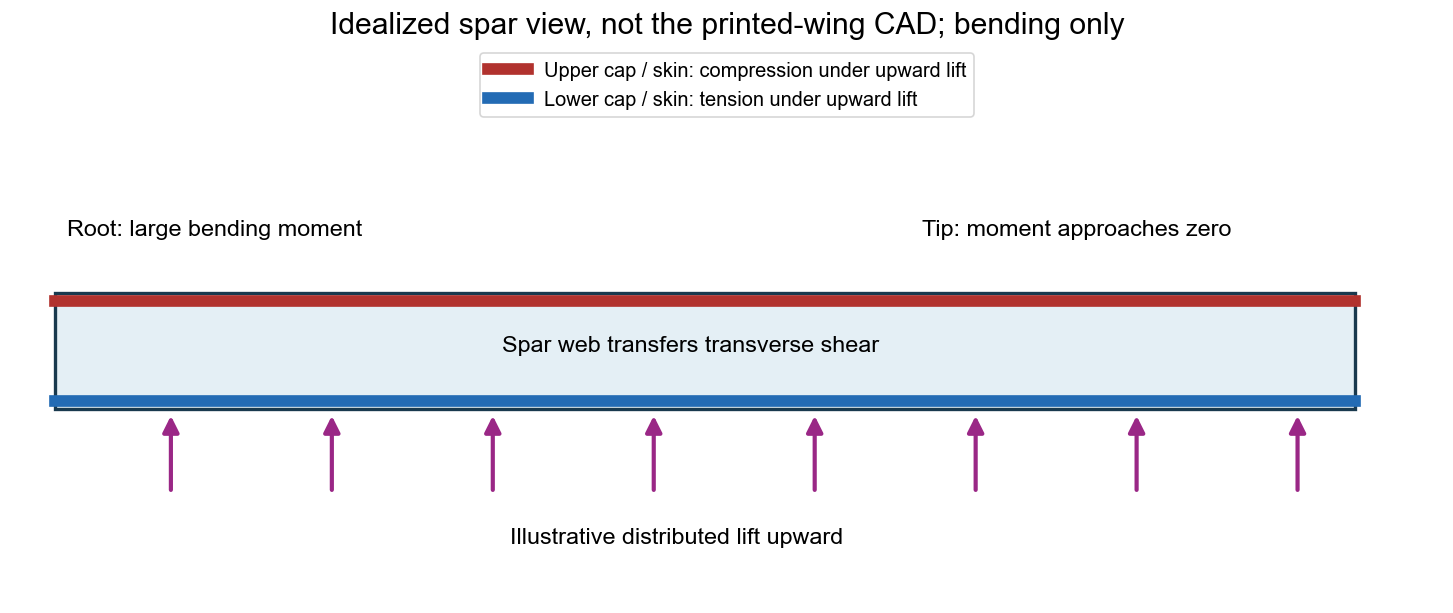

In [9]:
#@title Figure 8 — a wing spar turns bending into a separated force couple
fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
ax.add_patch(Rectangle((0,0),450,30,facecolor='#e4eff5',edgecolor='#19394e',lw=2))
ax.plot([0,450],[28,28],color='#b1322e',lw=7,label='Upper cap / skin: compression under upward lift')
ax.plot([0,450],[2,2],color='#236bb4',lw=7,label='Lower cap / skin: tension under upward lift')
for at in np.linspace(40,430,8): arrow(ax,(at,-22),(at,-1),'#9a2786')
ax.text(215,-35,'Illustrative distributed lift upward',ha='center')
ax.text(220,15,'Spar web transfers transverse shear',ha='center',fontsize=14)
ax.text(4,45,'Root: large bending moment',fontsize=14)
ax.text(300,45,'Tip: moment approaches zero',fontsize=14)
ax.set(xlim=(-15,480),ylim=(-50,95)); ax.axis('off'); ax.legend(loc='upper center',fontsize=12)
ax.set_title('Idealized spar view, not the printed-wing CAD; bending only')
plt.show()

## 9. Four-minute exit ticket and after-class practice

Submit one page with: a labelled free body; reaction unknowns and constraints; one equilibrium check; one moment-to-stress calculation; one deflection calculation; the app study record; and a sentence explaining the largest stress and displacement locations. Use units on every numerical result.

1. Why is root displacement zero while root stress can be largest?
2. Why do two 2 N loads have different moments and deflections?
3. Which extra information is needed for a fixed–fixed beam beyond equilibrium?
4. If an app returns zero deflection, where was the load placed and what motions were restrained?

**After class, not part of the 90-minute route:** change one parameter at a time. Predict and test $P\times2$, $E\times2$ and $h\times2$. Then explore the triangle/trapezoid options from Lecture 02, keeping total force fixed. Reactions and stress checks should precede vibration modes.

### Reading and model scope

[TU Delft beam theory and finite elements](https://teachbooks.tudelft.nl/computational-modelling/structural_linear/euler_bernouilli.html) supports the equilibrium–curvature–boundary-condition framework. Our diagrams are original instructional illustrations. Numerical examples use declared assumed dimensions/material values and closed-form elastic beam solutions, independently checked against the course beam engine. Scope: straight, slender, homogeneous solid section; constant $EI$; ideal supports; linear elasticity and small displacement; no self-weight unless specified. This is not an airworthiness or printed-wing failure certification.